# Hälsostudie
Av: Lovis Wikström

## Del 1 - Grundläggande analys och statistik

### 1. Introduktion
I denna rapporten undersöks data från en hälsostudie med 800 deltagare.
Vårt syfte är att analysera hälsorelaterade faktorer samt undersöka eventuella samband mellan exempelvis ålder, vikt, blodtryck, rökning och sjukdomsförekomst. 
Vi genomför analysen med hjälp av Python och vi använder oss av beskrivande statistik, visualiseringar, simuleringar, konfidensintervall och hypotesprövning för att undersöka och tolka datan.



### 2. Importering och inläsning
Här läses den datan vi utgår ifrån att läsas in, samt importerar de paket vi kommer att använda oss av i resten av rapporten.
Datasetet innehåller 800 unika deltagare och 9 variabler. Variablerna beskriver deltagarnas ålder, kön, längd, vikt, systoliska blodtryck, kolesterolvärden, rökvanor och sjukdomsförekomst.

Dessa variabler kommer att användas för att undersöka olika delar av deltagarnas hälsa.

In [27]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from scipy.stats import ttest_ind
np.random.seed(42)

df=pd.read_csv("../data/health_study_dataset.csv")

### 3. Översikt
Vi börjar med att undersöka datan vi har, här går vi igenom och tittar på och kontrollerar det vi jobbar med och ser till att allt är som det ska, att det inte finns dubletter och så vidare.
Vi börjar med att titta på hur många rader och kolumner vi har, samt de fem översta raderna för att få en idé om vad det är för data vi har att arbeta med.

In [28]:
print("Antal rader och kolumner:", df.shape)
df.head()

Antal rader och kolumner: (800, 9)


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


Här kontrolleras saknade värden och dubletter, samt kikar på deskriptiv statistik. 
Vi kan konstatera att det inte saknas några värden och att alla rader är unika, alltså förekommer inga dubletter.

För enkelhetens skull avrundar vi till två decimaler för att få en bättre överblick.

In [29]:
display(
    df.describe().round(2).rename(
        index={"50%": "median"}
    )
)

print("Saknade värden:")
print(df.isna().sum())
print("Dubletter:", df.duplicated().sum())


,id,age,height,weight,systolic_bp,cholesterol,disease
count,800.00,800.00,800.00,800.00,800.00,800.00,800.00
mean,400.50,49.43,171.85,73.41,149.18,4.93,0.06
std,231.08,14.50,9.80,13.69,12.79,0.85,0.24
min,1.00,18.00,144.40,33.70,106.80,2.50,0.00
25%,200.75,39.00,164.78,64.80,140.90,4.33,0.00
median,400.50,50.00,171.35,73.20,149.40,4.97,0.00
75%,600.25,59.00,178.92,82.60,157.60,5.48,0.00
max,800.00,90.00,200.40,114.40,185.90,7.88,1.00


Saknade värden:
id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64
Dubletter: 0


Datasetet består av 800 rader och 9 kolumner. 
Vid kontroll av datakvaliteten upptäcktes inga saknade värden eller dubletter, vilket innebär att samtliga observationer är unika och kompletta.

Medelåldern bland deltagarna är cirka 49,43 år och medianåldern är 50 år. Medelvikten är 73,41 kg och det genomsnittliga systoliska blodtrycket är 149,18 mmHg.


Genom att jämföra medelvärde och median kan vi få en uppfattning om hur värdena är fördelade, och vi kan se att de inte skiljer sig så mycket, vilket man kan tolka som att det är en jämn fördelning i vår data.

Här gör vi en sammanställning av median, medelvärde, minsta och största värde i kategorierna ålder, vikt, systoliskt blodtryck samt förekomst av sjukdom, vilket är de kolumner vi kommer att titta mest på, vi har redan värdena ovan, men detta ger oss en lite tydligare bild av just dessa. 

Även här avrundat till två decimaler.

In [30]:
columns = [
        "age", "weight", "systolic_bp", "disease", "cholesterol", "height"]

df[columns].agg(["mean", "median", "min", "max"]).round(2)

,age,weight,systolic_bp,disease,cholesterol,height
mean,49.43,73.41,149.18,0.06,4.93,171.85
median,50.00,73.20,149.40,0.00,4.97,171.35
min,18.00,33.70,106.80,0.00,2.50,144.40
max,90.00,114.40,185.90,1.00,7.88,200.40


### 4. Visualisering
Här undersöker vi deltagarnas hälsodata med hjälp av visualiseringar i fyra olika diagram.
##### 4.1. Histogram: Fördelningen av systoliskt blodtryck. 

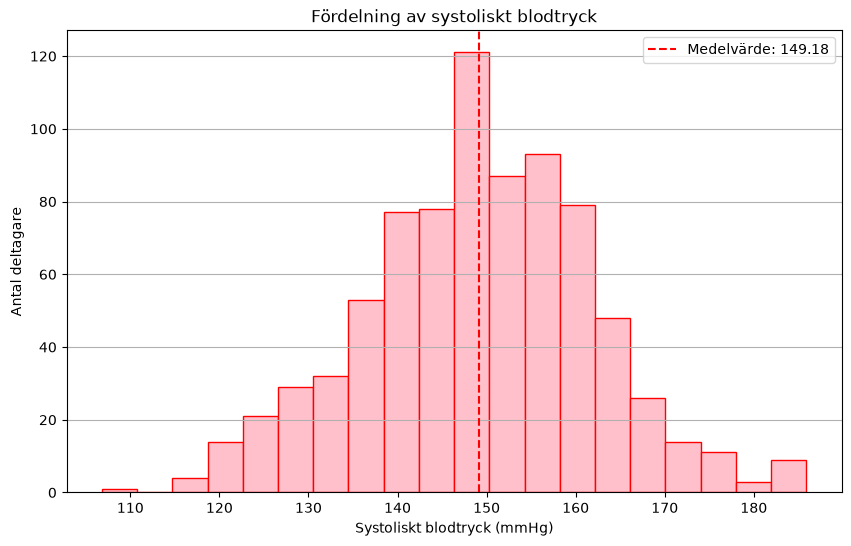

In [31]:
plt.figure(figsize=(10, 6))
plt.hist(df["systolic_bp"], bins=20, color="pink", edgecolor="red")
mean_bp = df["systolic_bp"].mean()

plt.axvline(mean_bp, color="red", linestyle="--", label=f"Medelvärde: {mean_bp:.2f}")
plt.legend()
plt.title("Fördelning av systoliskt blodtryck")
plt.xlabel("Systoliskt blodtryck (mmHg)")
plt.ylabel("Antal deltagare")
plt.grid(axis="y")
plt.show()

Histogrammet visar hur deltagarnas systoliska blodtryck är fördelat. Genom att visualisera fördelningen blir det lättare att se var de flesta observationerna ligger och om det finns några ovanligt höga eller låga värden.

Medelvärdet för det systoliska blodtrycket är cirka 149,18 mmHg. Diagrammet ger en bild av hur blodtrycksvärdena varierar runt medelvärdet.
Vi ser medelvärdet markerat i histogrammet. 

##### 4.2. Låddiagram: Viktfördelningen per kön.

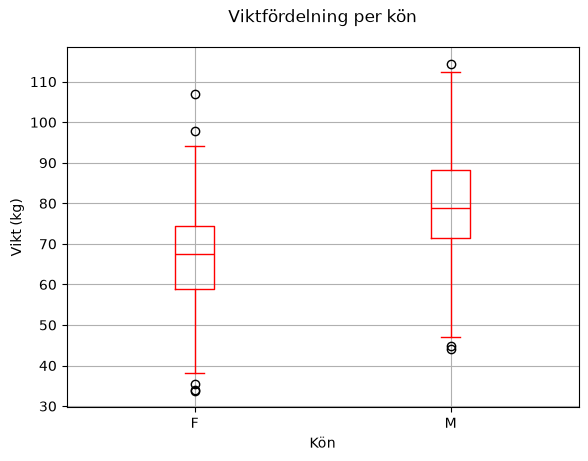

In [32]:
fig, ax = plt.subplots()
df.boxplot(column="weight", by="sex", ax=ax, color="red")

fig.suptitle("Viktfördelning per kön")

ax.set_title("")
ax.set_xlabel("Kön")
ax.set_ylabel("Vikt (kg)")

plt.show()

Här använder vi ett låddiagram för att jämföra viktfördelningen mellan kvinnor och män i detta dataset.

Genom att jämföra medianen, spridningen och eventuella avvikande värden kan vi identifiera om det finns skillnader mellan grupperna.

##### 4.3. Stapeldiagram: Fördelningen mellan rökare/icke-rökare.

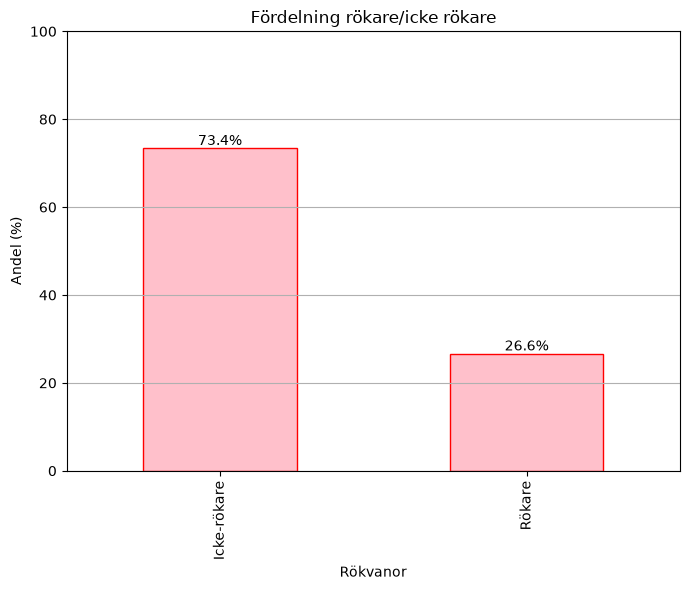

In [33]:
smoker_percent = df["smoker"].value_counts(normalize=True) * 100
smoker_percent = smoker_percent.rename({
    "No": "Icke-rökare",
    "Yes": "Rökare"
})
smoker_percent.plot(
    kind="bar",
    color="pink",
    edgecolor="red",
    figsize=(7,6)
    )
plt.grid(axis="y")
plt.title("Fördelning rökare/icke rökare")
plt.xlabel("Rökvanor")
plt.ylabel("Andel (%)")
plt.ylim(0, 100)
plt.bar_label(plt.gca().containers[0], fmt="%.1f%%")
plt.tight_layout()
plt.show()

Stapeldiagrammet visar fördelningen mellan rökare och icke-rökare bland deltagarna i detta dataset.

Av totalt 800 deltagare är 213 (26,6%) rökare och 587 (73,4%) icke-rökare. Det innebär att majoriteten av deltagarna i undersökningen inte röker.

Diagrammet gör det enkelt att jämföra gruppernas storlek och ger oss en överblick över hur rökvanorna är fördelade i detta dataset.

##### 4.4. Spridningsdiagram: Sambandet mellan ålder och systoliskt blodtryck.
Visas här med den linjära regressionen. 

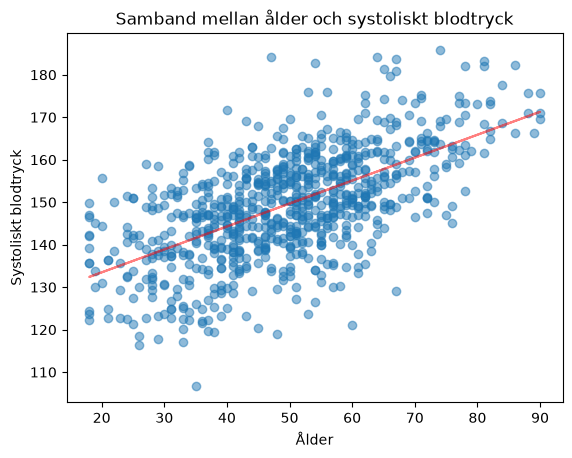

Det förväntade systoliska blodtrycket ökar med cirka 0.54 mmHg / år.


In [34]:
plt.scatter(df["age"], df["systolic_bp"], alpha=0.5)
plt.title("Samband mellan ålder och systoliskt blodtryck")
plt.xlabel("Ålder")
plt.ylabel("Systoliskt blodtryck")

x = df["age"]
y = df["systolic_bp"]
k, m = np.polyfit(x, y, 1).round(2)

plt.plot(x, k*x + m, color="red", alpha=0.5)
plt.show()
print("Det förväntade systoliska blodtrycket ökar med cirka", k, "mmHg / år.")

Spridningsdiagrammet visar sambandet mellan deltagarnas ålder och systoliskt blodtryck.

Regressionslinjen har en positiv lutning på cirka 0,54, vilket innebär att det förväntade systoliska blodtrycket enligt modellen ökar med ungefär 0,54 mmHg för varje ytterligare levnadsår.

Detta tyder på ett positivt samband mellan ålder och systoliskt blodtryck i datasetet. Observera dock att ett samband inte automatiskt innebär att ålder är den enda faktorn som påverkar blodtrycket.

Spridningen mellan observationerna visar också att deltagare i samma ålder kan ha olika blodtryck.

### 5. Sjukdomsförekomst
I denna delen kikar vi närmre på sjukdomsförekomsten. 
Vi tar reda på hur ofta det förekommer och undersöker om det finns någon effekt av slumpmässig variation.

In [35]:
disease_rate = df["disease"].mean()
print(f"Dokumenterad andel med sjukdom: {disease_rate:.2%} av {len(df)} deltagare.")
print(f"Antal deltagare med sjukdomen i undersökningen är {df["disease"].sum()}.")



Dokumenterad andel med sjukdom: 5.88% av 800 deltagare.
Antal deltagare med sjukdomen i undersökningen är 47.


Vi undersöker slumpmässig variation genom att göra en simulering.

In [36]:
rng = np.random.default_rng(42)

sim_disease = rng.binomial(
    n=1,
    p= disease_rate,
    size=1000
)
dif_disease = (disease_rate - sim_disease.mean()) * 100
print(f"Dokumenterad andel med sjukdom: {disease_rate:.2%}")
print(f"Simulerade andelen med sjukdom: {sim_disease.mean():.2%}")
print(f"Skillnaden mellan dokumenterade och simulerade fall: {dif_disease:.2f} procentenheter.")


Dokumenterad andel med sjukdom: 5.88%
Simulerade andelen med sjukdom: 5.40%
Skillnaden mellan dokumenterade och simulerade fall: 0.47 procentenheter.


Den dokumenterade sjukdomsförekomsten i detta dataset är 5,88%, vilket motsvarar 47 av 800 deltagare.

För att undersöka hur slumpmässig variation kan påverka resultatet genomfördes en simulering med 1 000 observationer. I simuleringen blev sjukdomsförekomsten 5,40%.

Skillnaden mellan den dokumenterade och simulerade andelen är ungefär 0,47 procentenheter, vilket visar att vi har fått ett resultat nära den verkliga sjukdomsförekomsten.

Detta visar att resultatet kan variera något på grund av slumpmässiga faktorer, även när samma sannolikhet används som utgångspunkt. Den simulerade andelen behöver därför inte bli exakt densamma som den observerade andelen.

### 6. Konfidensintervall: systoliskt blodtryck
Här räknar vi ett konfidensintervall på 95% för systoliskt blodtryck. 
Vi använder oss av normalapproximation. 


In [37]:
bp = df["systolic_bp"]

mean_bp = bp.mean()
std_bp = bp.std(ddof=1)
n = bp.count()
se = std_bp / np.sqrt(n)
lower = mean_bp - 1.96 * se
upper = mean_bp + 1.96 * se

print(f"Medelvärde: {mean_bp:.2f} mmHg")
print(f"Standardavvikelse: {std_bp:.2f} mmHg")
print(f"Antal personer: {n}")
print(f"Standardfel: {se:.2f} mmHg")
print(f"95% konfidensintervall: {lower:.2f} - {upper:.2f} mmHg")

Medelvärde: 149.18 mmHg
Standardavvikelse: 12.79 mmHg
Antal personer: 800
Standardfel: 0.45 mmHg
95% konfidensintervall: 148.29 - 150.07 mmHg


Ett 95-procentigt konfidensintervall beräknas för att uppskatta inom vilket intervall det sanna medelvärdet i populationen skulle kunna förväntas ligga.

Det beräknade intervallet är cirka 148,29–150,07 mmHg.

Det betyder att vi med 95% konfidens uppskattar att populationens genomsnittliga systoliska blodtryck ligger inom detta intervall.

Ett smalare intervall innebär generellt en mer precis uppskattning, medan ett bredare intervall innebär större osäkerhet.

### 7. Hypotesprövning
Syftet med hypotesprövningen är att undersöka om det finns statistiskt stöd för att rökare har ett högre genomsnittligt systoliskt blodtryck än icke-rökare.
Följande hypoteser testas:

Nollhypotes (H0): Det finns ingen skillnad i systoliskt blodtryck mellan rökare/icke-rökare.

Alternativhypotes (H1): Rökare har generellt högre genomsnittligt systoliskt blodtryck än icke-rökare.

För att undersöka detta används ett ensidigt Welch t-test. Testet passar eftersom vi jämför medelvärdet mellan två oberoende grupper och inte förutsätter att grupperna har samma varians.

Signifikansnivån sätts till 5 % (0,05). P-värdet används sedan för att avgöra om det finns tillräckligt statistiskt stöd för att förkasta nollhypotesen.

In [38]:
smokers = df[df["smoker"] == "Yes"]["systolic_bp"]
non_smokers = df[df["smoker"] == "No"]["systolic_bp"]
dif_bp = dif_bp = smokers.mean() - non_smokers.mean()

print(f"Antal rökare: {len(smokers)}")
print(f"Medelblodtryck för rökare: {smokers.mean().round(2)} mmHg")
print(f"Antal icke-rökare: {len(non_smokers)}")
print(f"Medelblodtryck för icke-rökare: {non_smokers.mean().round(2)} mmHg")
print(f"Skillnad i blodtryck mellan rökare/icke-rökare: {dif_bp:.2f} mmHg")

Antal rökare: 213
Medelblodtryck för rökare: 149.52 mmHg
Antal icke-rökare: 587
Medelblodtryck för icke-rökare: 149.05 mmHg
Skillnad i blodtryck mellan rökare/icke-rökare: 0.47 mmHg


In [39]:
df.groupby("smoker")["systolic_bp"].agg(
    ["count", "mean", "std", "median"]
).round(2)

,count,mean,std,median
smoker,,,,
No,587,149.05,12.63,149.3
Yes,213,149.52,13.27,149.5


In [40]:
smoker_bp = df.loc[df["smoker"] == "Yes", "systolic_bp"].dropna()
non_smoker_bp = df.loc[df["smoker"] == "No", "systolic_bp"].dropna()
alpha = 0.05


t_stat, p_value = ttest_ind(smoker_bp, non_smoker_bp, equal_var=False, alternative="greater")
difference_bp = smoker_bp.mean() - non_smoker_bp.mean()

print(f"t-värde: {t_stat:.4f}")
print(f"p-värde: {p_value:.4f}")
print("Observerad skillnad rökare - icke-rökare:", difference_bp.round(4), "mmHg")


if p_value < alpha:
    print("Resultat: H0 förkastas på 5%-nivån.")
    print("Det finns statistisk signifikans som stöd för att rökare har högre medelblodtryck.")
else:
    print("Resultat: H0 kan inte förkastas på 5%-nivån.")
    print("Det finns inte statistisk signifikans som stöd för att rökare har ett högre medelblodtryck.")


t-värde: 0.4503
p-värde: 0.3264
Observerad skillnad rökare - icke-rökare: 0.4719 mmHg
Resultat: H0 kan inte förkastas på 5%-nivån.
Det finns inte statistisk signifikans som stöd för att rökare har ett högre medelblodtryck.


Resultatet visar att rökare har ett något högre genomsnittligt systoliskt blodtryck än icke-rökare. Skillnaden mellan grupperna är cirka 0,47 mmHg.

P-värdet är 0,3264, vilket är högre än signifikansnivån 0,05. Det innebär att nollhypotesen inte kan förkastas.

Därför finns det inte tillräckligt statistiskt stöd för att rökare har ett högre genomsnittligt systoliskt blodtryck än icke-rökare i detta dataset.

### 8. Slutsats

I denna hälsostudie har vi undersökt 800 deltagares hälsodata med hjälp av statistiska metoder och visualiseringar.

Analysen har gett oss en överblick över deltagarnas hälsa och visat hur olika faktorer så som ålder, vikt, blodtryck och rökvanor kan undersökas med hjälp av dataanalys.

Vi kunde se ett positivt samband mellan ålder och systoliskt blodtryck. Däremot visade hypotesprövningen inte tillräckligt statistiskt stöd för att rökare har ett högre genomsnittligt blodtryck än icke-rökare.

Sammanfattningsvis har analysen visat hur beskrivande statistik, visualiseringar och statistiska tester kan användas för att förstå och undersöka hälsodata.